<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/video4_tiempo_en_fila_yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⏱️ Entrené una IA para medir cuánto esperas en la fila
**Laboratorio de Códigos** · YOLO + ByteTrack + zona en OpenCV

Usa un video propio o de stock libre (Pexels, Pixabay) de una fila vista desde arriba o en diagonal. Activa GPU T4.

In [ ]:
!pip install -q ultralytics

In [ ]:
from google.colab import files
subido = files.upload()          # sube el video de la fila
VIDEO_IN = next(iter(subido))

Saving 16920949_2160_3840_30fps.mp4 to 16920949_2160_3840_30fps.mp4


## 1. Dibuja la zona de la fila
Mira el primer cuadro con la cuadrícula y ajusta las esquinas de `ZONA` (en fracciones del ancho y alto: 0 = izquierda/arriba, 1 = derecha/abajo).

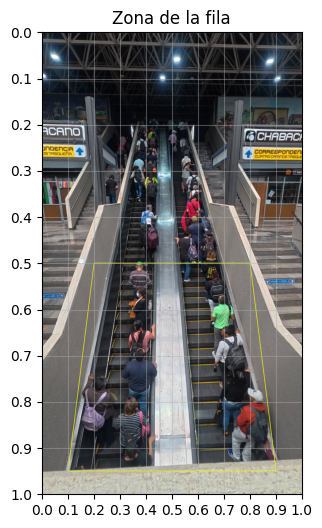

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt

cap = cv2.VideoCapture(VIDEO_IN)
ok, primer = cap.read(); cap.release()
H, W = primer.shape[:2]

ZONA = [(0.20, 0.50), (0.80, 0.50), (0.90, 0.95), (0.10, 0.95)]   # <- ajusta
poligono = np.array([(int(x * W), int(y * H)) for x, y in ZONA], np.int32)

vista = primer.copy()
cv2.polylines(vista, [poligono], True, (0, 255, 255), 4)
plt.figure(figsize=(10, 6)); plt.imshow(vista[:, :, ::-1])
plt.xticks(np.linspace(0, W, 11), [f"{v:.1f}" for v in np.linspace(0, 1, 11)])
plt.yticks(np.linspace(0, H, 11), [f"{v:.1f}" for v in np.linspace(0, 1, 11)])
plt.grid(alpha=0.4); plt.title("Zona de la fila"); plt.show()

## 2. Seguimiento y tiempos
- YOLO detecta solo personas (clase 0) y **ByteTrack** le da a cada una un ID que se mantiene entre cuadros.
- Una persona está "en la fila" si sus **pies** (centro inferior de la caja) caen dentro de la zona.
- Si alguien sale de la zona más de `GRACIA_S` segundos, su espera se cierra y entra al promedio. Así una oclusión breve no reinicia el cronómetro.

In [ ]:
from ultralytics import YOLO

modelo = YOLO("yolo26s.pt")     # o "yolo11s.pt"
GRACIA_S = 1.5

cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
out = cv2.VideoWriter("fila_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

entrada, ultimo, esperas = {}, {}, []   # id -> cuadro de entrada / último cuadro en zona
cuadro = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = modelo.track(frame, persist=True, tracker="bytetrack.yaml", classes=[0], conf=0.3, verbose=False)[0]

    en_fila = []
    if r.boxes.id is not None:
        for (x1, y1, x2, y2), tid in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().tolist()):
            pies = (float((x1 + x2) / 2), float(y2))
            dentro = cv2.pointPolygonTest(poligono, pies, False) >= 0
            if dentro:
                entrada.setdefault(tid, cuadro)
                ultimo[tid] = cuadro
                en_fila.append(tid)
                seg = (cuadro - entrada[tid]) / fps
                col = (0, 200, 255) if seg < 60 else (0, 0, 255)
                cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), col, 3)
                cv2.putText(frame, f"#{tid} {seg:.0f}s", (int(x1), int(y1) - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.9, col, 3)
            else:
                cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), (150, 150, 150), 1)

    # cerrar esperas de quien ya salió de la fila
    for tid in [t for t in entrada if cuadro - ultimo[t] > GRACIA_S * fps]:
        esperas.append((ultimo[tid] - entrada.pop(tid)) / fps)
        ultimo.pop(tid)

    # zona semitransparente
    capa = frame.copy()
    cv2.fillPoly(capa, [poligono], (0, 255, 255))
    frame = cv2.addWeighted(capa, 0.15, frame, 0.85, 0)
    cv2.polylines(frame, [poligono], True, (0, 255, 255), 3)

    # panel
    prom = f"{np.mean(esperas):.0f} s" if esperas else "calculando..."
    cv2.rectangle(frame, (0, 0), (W, 120), (30, 30, 30), -1)
    cv2.putText(frame, f"En fila: {len(en_fila)}", (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 3)
    cv2.putText(frame, f"Espera promedio: {prom}", (20, 100), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 255, 255), 3)
    out.write(frame)
    cuadro += 1

# quienes seguían en la fila al terminar el video
for tid in entrada:
    esperas.append((ultimo[tid] - entrada[tid]) / fps)
cap.release(); out.release()
print(f"Personas medidas: {len(esperas)}  |  Espera promedio: {np.mean(esperas):.1f} s  |  Máxima: {max(esperas, default=0):.1f} s")

Personas medidas: 70  |  Espera promedio: 2.4 s  |  Máxima: 7.1 s


In [ ]:
SALIDA = "fila_ia.mp4"
!ffmpeg -y -loglevel error -i fila_raw.mp4 -c:v libx264 -preset veryfast -pix_fmt yuv420p {SALIDA}
from base64 import b64encode
from IPython.display import HTML
datos = b64encode(open(SALIDA, "rb").read()).decode()
HTML(f'<video width=720 controls autoplay loop><source src="data:video/mp4;base64,{datos}" type="video/mp4"></video>')

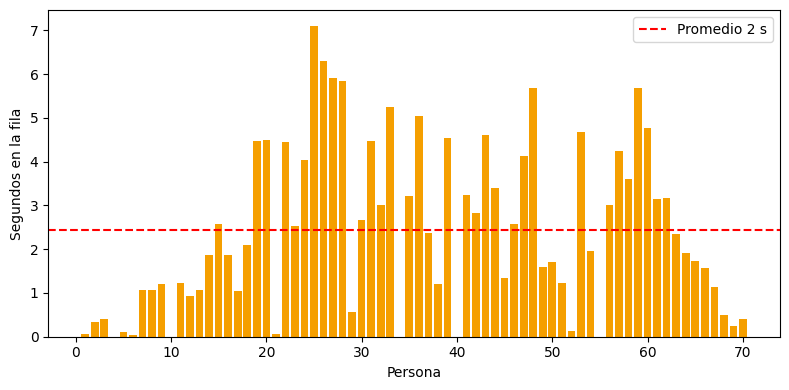

In [ ]:
# Gráfica de esperas por persona (buen cierre para el video)
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(esperas) + 1), esperas, color="#f59f00")
plt.axhline(np.mean(esperas), color="red", ls="--", label=f"Promedio {np.mean(esperas):.0f} s")
plt.xlabel("Persona"); plt.ylabel("Segundos en la fila"); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
files.download(SALIDA)

**Para ajustar:** si los IDs cambian mucho (la misma persona cuenta dos veces), sube `GRACIA_S` o usa un modelo más grande (`yolo26m.pt`). Ten en cuenta que los videos cortos de stock solo muestran parte de la espera real.